In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [89]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [90]:
base_path = r"C:\kdt_0900_osh\ml\resource\datasets"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [91]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [92]:
class_dict = dict(enumerate(train_dataset.classes))

## 실습

In [93]:
train_size = len(train_dataset)
test_size = len(test_dataset)
total_size = train_size + test_size

In [94]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [95]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64)

In [96]:
imgs, labels = next(iter(train_dataloader))

In [97]:
print(imgs.size())

torch.Size([64, 1, 64, 64])


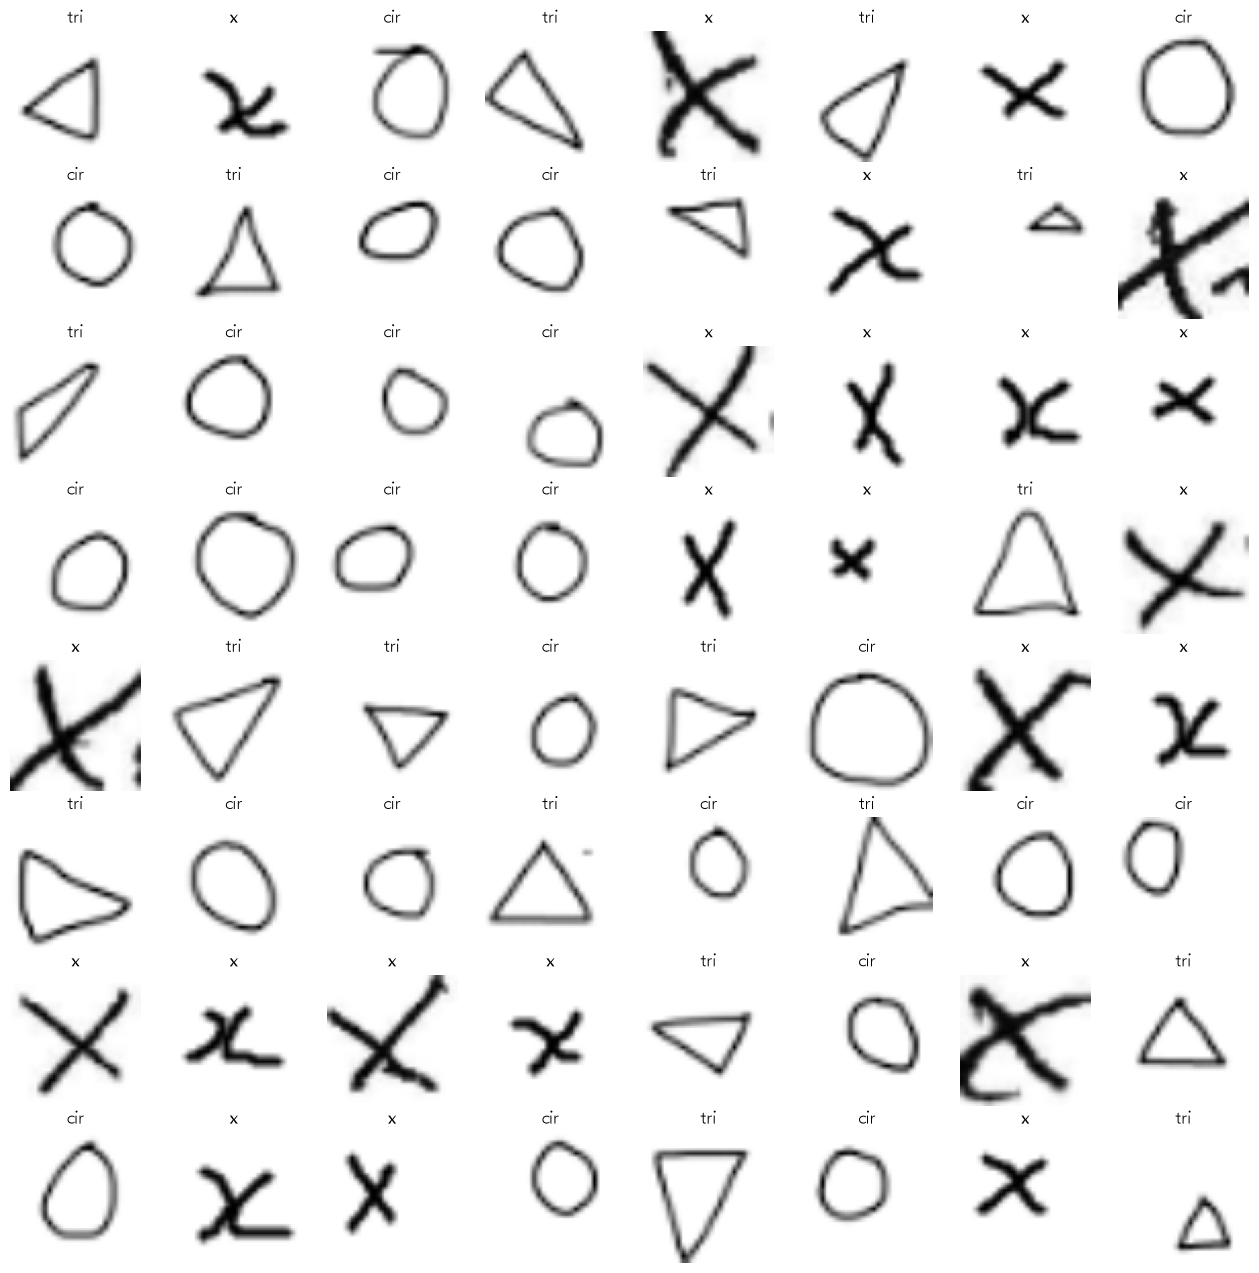

In [98]:
fig, axes = plt.subplots(8,8,figsize=(16,16))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64,64), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.show()

In [99]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


In [100]:
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNenuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 14, kernel_size=3, padding="same"),  # 64, 64 -> 66, 66 -> 64, 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            nn.Conv2d(14, 14, kernel_size=3, padding="same"),  # feature의 개수를 1개에서 28개로 늘림
            nn.ReLU(), 
            nn.MaxPool2d(kernel_size=2),  # 2 X 2 크기로 max pooling -> 32, 32
            nn.Dropout(0.25),  # dropout을 통해 과대적합을 예방하여 일반화 성능 up
            nn.Conv2d(14, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 10)
        
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [101]:
model = ConvNenuralNetwork().to(device)

In [102]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [103]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item()
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [104]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        outputs = model(imgs)
        loss = criterion(outputs, labels)

        batch_size = imgs.size(0)
        running_loss += loss.item()
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

    return running_loss / total, running_corrects / total

In [105]:
epochs = 30

for i in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i + 1}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x7168 and 14336x10)